# A/B-тест Cookie Cats: перенос ворот с 30-го на 40-й уровень

В игре Cookie Cats на определенном уровне стоят ворота, игрок должен подождать или заплатить, чтобы играть дальше. Проверяем, что будет, если перенести первые ворота с 30-го уровня на 40-й.

**Данные:** `cookie_cats.csv` (Kaggle: "Mobile Games A/B Testing - Cookie Cats"), колонки `userid`, `version` (gate_30 / gate_40), `sum_gamerounds`, `retention_1`, `retention_7`.

## 1. Гипотеза и метрики

- **Контроль:** gate_30 (ворота на 30-м уровне, текущая версия)
- **Тест:** gate_40 (ворота на 40-м уровне)
- **Основные метрики:** удержание 1-го дня (retention_1) и 7-го дня (retention_7)
- **Вспомогательная метрика:** число сыгранных раундов (sum_gamerounds)

**H0:** доля вернувшихся игроков в двух группах одинакова.
**H1:** доли различаются (двусторонняя проверка).

**Уровень значимости:** α = 0.05. Метрик две, поэтому дополнительно применяем
поправку Бонферрони: α = 0.05 / 2 = 0.025 на каждую.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
import sqlite3

DATA_PATH = "./data/cookie_cats.csv"
ALPHA = 0.05
ALPHA_ADJ = ALPHA / 2  # поправка Бонферрони на две метрики

## 2. Загрузка и проверка качества данных

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


### Полнота: пропуски

In [3]:
print("Пропуски по колонкам:")
print(df.isna().sum())

Пропуски по колонкам:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64


### Дубли

In [4]:
print("\nДубли userid:", df["userid"].duplicated().sum())
print("Полностью одинаковые строки:", df.duplicated().sum())


Дубли userid: 0
Полностью одинаковые строки: 0


### Корректность значений

In [5]:
print("\nУникальные версии:", df["version"].unique())
print("Отрицательные раунды:", (df["sum_gamerounds"] < 0).sum())
print("Игроков с 0 раундов:", (df["sum_gamerounds"] == 0).sum())
print("\nТипы данных:")
print(df.dtypes)


Уникальные версии: <StringArray>
['gate_30', 'gate_40']
Length: 2, dtype: str
Отрицательные раунды: 0
Игроков с 0 раундов: 3994

Типы данных:
userid            int64
version             str
sum_gamerounds    int64
retention_1        bool
retention_7        bool
dtype: object


### Выбросы в числе раундов

In [6]:
print(df["sum_gamerounds"].describe())
print("\nТоп-5 значений sum_gamerounds:")
print(df["sum_gamerounds"].sort_values(ascending=False).head(5).to_string())

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

Топ-5 значений sum_gamerounds:
57702    49854
7912      2961
29417     2640
43671     2438
48188     2294


В данных есть явный выброс (один игрок с десятками тысяч раундов). Для метрик
удержания он не важен (это 0/1), но искажает среднее число раундов.
Поэтому для раундов используем медиану и непараметрический тест, а выброс
исключаем только из визуализации.

## 3. Проверка разбиения на группы (SRM)

Если пользователи распределены по группам случайно, размеры групп должны быть
близки к 50/50. Сильный перекос (Sample Ratio Mismatch) говорит о проблеме в
рандомизации, и результатам теста тогда доверять нельзя.

In [7]:
counts = df["version"].value_counts().sort_index()
print(counts)

chi2, p_srm = stats.chisquare(counts.values) # ожидаем равные доли
print(f"\nSRM-проверка: chi2 = {chi2:.3f}, p = {p_srm:.4f}")
print("Вывод:", "разбиение корректно (p > 0.01)" if p_srm > 0.01
      else "перекос в разбиении!")

version
gate_30    44700
gate_40    45489
Name: count, dtype: int64

SRM-проверка: chi2 = 6.902, p = 0.0086
Вывод: перекос в разбиении!


Проверка разбиения на группы выявила небольшой перекос (44 700 и 45 489 игроков, p = 0.0086). Он совсем маленький, поэтому не учитываем. В реальном тесте стоит выяснить причину перекоса до интерпретации.

## 4. Дизайн теста: размер выборки и длительность

Сколько игроков нужно на группу, чтобы заметить относительное изменение
удержания 7-го дня? Берём базовое значение из контрольной группы.

In [8]:
base_r7 = df.loc[df["version"] == "gate_30", "retention_7"].mean()
print(f"Базовое удержание 7-го дня: {base_r7:.3%}")

power_analysis = NormalIndPower()
for rel_lift in [0.02, 0.05, 0.10]:
    target = base_r7 * (1 + rel_lift)
    es = proportion_effectsize(target, base_r7)
    n = power_analysis.solve_power(effect_size=es, alpha=ALPHA, power=0.8,
                                   ratio=1, alternative="two-sided")
    print(f"Относительный прирост {rel_lift:.0%} "
          f"({base_r7:.2%} -> {target:.2%}): нужно {int(np.ceil(n)):,} игроков на группу")

print(f"\nФактически в тесте: {counts.min():,} игроков в меньшей группе")

Базовое удержание 7-го дня: 19.020%
Относительный прирост 2% (19.02% -> 19.40%): нужно 168,357 игроков на группу
Относительный прирост 5% (19.02% -> 19.97%): нужно 27,238 игроков на группу
Относительный прирост 10% (19.02% -> 20.92%): нужно 6,932 игроков на группу

Фактически в тесте: 44,700 игроков в меньшей группе


**Длительность.** Метрика retention_7 требует, чтобы каждый игрок «прожил»
7 дней после установки. Значит, тест нужно вести минимум 7 дней после
набора последнего игрока. Лучше захватить полные недели (7 или 14 дней),
чтобы учесть недельную сезонность поведения.

## 5. Анализ метрик удержания

In [9]:
def analyze_retention(df, metric, alpha=ALPHA_ADJ):
    ctrl = df.loc[df["version"] == "gate_30", metric].astype(int)
    test = df.loc[df["version"] == "gate_40", metric].astype(int)

    n = np.array([len(ctrl), len(test)])
    x = np.array([ctrl.sum(), test.sum()])
    p = x / n

    z, pval = proportions_ztest(x, n) # двусторонний z-тест для долей

    diff = p[1] - p[0]
    se = np.sqrt(p[0] * (1 - p[0]) / n[0] + p[1] * (1 - p[1]) / n[1])
    ci = (diff - 1.96 * se, diff + 1.96 * se)

    # Для сравнения хи-квадрат на таблице сопряженности
    table = pd.crosstab(df["version"], df[metric])
    chi2, p_chi, _, _ = stats.chi2_contingency(table, correction=False)

    return {
        "metric": metric,
        "gate_30": p[0], "gate_40": p[1],
        "diff_abs": diff, "diff_rel": diff / p[0],
        "ci_low": ci[0], "ci_high": ci[1],
        "z": z, "p_ztest": pval, "p_chi2": p_chi,
        "significant": pval < alpha,
    }

results = pd.DataFrame([analyze_retention(df, m) for m in ["retention_1", "retention_7"]])
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(results.T)
results.T

                       0            1
metric       retention_1  retention_7
gate_30           0.4482       0.1902
gate_40           0.4423       0.1820
diff_abs         -0.0059      -0.0082
diff_rel         -0.0132      -0.0431
ci_low           -0.0124      -0.0133
ci_high           0.0006      -0.0031
z                 1.7841       3.1644
p_ztest           0.0744       0.0016
p_chi2            0.0744       0.0016
significant        False         True


,0,1
metric,retention_1,retention_7
gate_30,0.4482,0.1902
gate_40,0.4423,0.1820
diff_abs,-0.0059,-0.0082
diff_rel,-0.0132,-0.0431
ci_low,-0.0124,-0.0133
ci_high,0.0006,-0.0031
z,1.7841,3.1644
p_ztest,0.0744,0.0016
p_chi2,0.0744,0.0016


### Визуализация

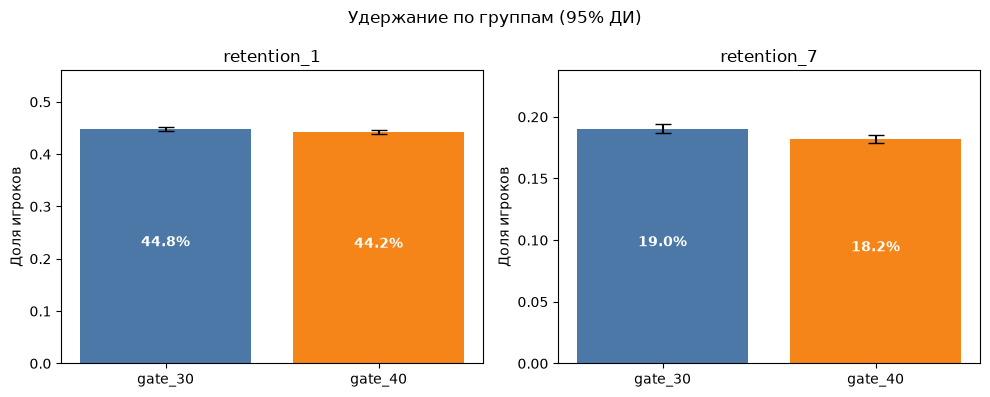

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ["retention_1", "retention_7"]):
    rates, errs = [], []
    for v in ["gate_30", "gate_40"]:
        s = df.loc[df["version"] == v, metric].astype(int)
        lo, hi = proportion_confint(s.sum(), len(s), alpha=ALPHA, method="normal")
        rates.append(s.mean())
        errs.append((hi - lo) / 2)
    ax.bar(["gate_30", "gate_40"], rates, yerr=errs, capsize=6,
           color=["#4C78A8", "#F58518"])
    ax.set_title(metric)
    ax.set_ylabel("Доля игроков")
    ax.set_ylim(0, max(rates) * 1.25)
    for i, r in enumerate(rates):
        ax.text(i, r / 2, f"{r:.1%}", ha="center", color="white", fontweight="bold")
plt.suptitle("Удержание по группам (95% ДИ)")
plt.tight_layout()
plt.savefig("retention_by_group.png", dpi=150)
plt.show()

## 6. Бутстрап как проверка

Независимо от z-теста оценим разницу удержания 7-го дня через бутстрап:
много раз пересэмплируем игроков и смотрим на разброс разницы.

Бутстрап-ДИ для разницы (gate_40 - gate_30), retention_7: [-0.0133, -0.0032]
Ноль внутри интервала? False


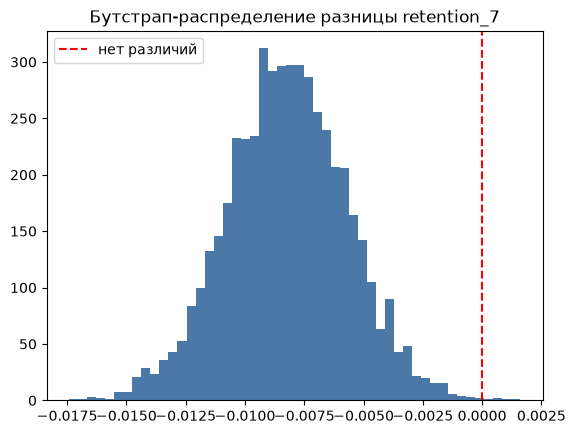

In [11]:
rng = np.random.default_rng(42)
c = df.loc[df["version"] == "gate_30", "retention_7"].astype(int).values
t = df.loc[df["version"] == "gate_40", "retention_7"].astype(int).values

boot_diffs = np.empty(5000)
for i in range(5000):
    boot_diffs[i] = (rng.choice(t, len(t)).mean() - rng.choice(c, len(c)).mean())

lo, hi = np.percentile(boot_diffs, [2.5, 97.5])
print(f"Бутстрап-ДИ для разницы (gate_40 - gate_30), retention_7: "
      f"[{lo:.4f}, {hi:.4f}]")
print("Ноль внутри интервала?", lo <= 0 <= hi)

plt.hist(boot_diffs, bins=50, color="#4C78A8")
plt.axvline(0, color="red", linestyle="--", label="нет различий")
plt.title("Бутстрап-распределение разницы retention_7")
plt.legend()
plt.savefig("bootstrap_retention7.png", dpi=150)
plt.show()

## 7. Вспомогательная метрика: число раундов

Распределение сильно скошено (много игроков с малым числом раундов, длинный
хвост), поэтому используем медиану и тест Манна-Уитни, а не t-тест.

Медиана раундов: gate_30 = 17.0 | gate_40 = 16.0
Среднее раундов: gate_30 = 52.5 | gate_40 = 51.3
Манн-Уитни: U = 1,024,331,250, p = 0.0502


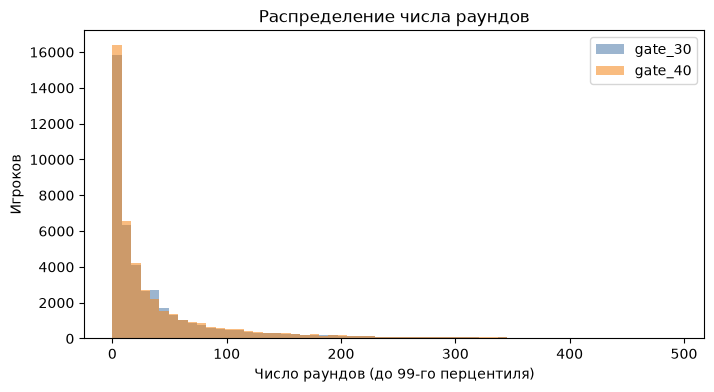

In [12]:
g30 = df.loc[df["version"] == "gate_30", "sum_gamerounds"]
g40 = df.loc[df["version"] == "gate_40", "sum_gamerounds"]

print("Медиана раундов: gate_30 =", g30.median(), "| gate_40 =", g40.median())
print("Среднее раундов: gate_30 = %.1f | gate_40 = %.1f" % (g30.mean(), g40.mean()))

u, p_mw = stats.mannwhitneyu(g30, g40, alternative="two-sided")
print(f"Манн-Уитни: U = {u:,.0f}, p = {p_mw:.4f}")

# Визуализация без выброса (обрезаем по 99-му перцентилю)
cap = df["sum_gamerounds"].quantile(0.99)
plt.figure(figsize=(8, 4))
for v, color in [("gate_30", "#4C78A8"), ("gate_40", "#F58518")]:
    s = df.loc[(df["version"] == v) & (df["sum_gamerounds"] <= cap), "sum_gamerounds"]
    plt.hist(s, bins=60, alpha=0.55, label=v, color=color)
plt.xlabel("Число раундов (до 99-го перцентиля)")
plt.ylabel("Игроков")
plt.legend()
plt.title("Распределение числа раундов")
plt.savefig("gamerounds_hist.png", dpi=150)
plt.show()

## 8. Выводы и рекомендация

1. **Retention 1-го дня:** gate_30 = 44.82%, gate_40 = 44.23%, разница -0.59 п.п. (ДИ [-1.24;+0.06]), p = 0.0744.
   Не значима при α = 0.025, интервал включает ноль.
2. **Retention 7-го дня:** gate_30 = 19.02%, gate_40 = 18.20%, разница -0.82 п.п. (ДИ [-1.33;-0.31]), p = 0.0016.
   Значима при α = 0.025, падение на 4.3% относительно контроля.
3. **Раунды:** медианы 17 (gate_30) и 16 (gate_40), p = 0.0502 по Манну-Уитни, различие не значимо, но сходится на границе.

**Рекомендация:** оставить ворота на 30-м уровне. Перенос на 40-й не улучшает удержание, а на 7-й день ухудшает его. Разница небольшая (меньше 1 п.п.), но на такой аудитории она устойчива и подтверждается двумя методами.

**Ограничения теста:** нет данных о монетизации (платежах), нет информации о длительности теста и датах, удержание 7 дня измеряется только для игроков, у которых прошла неделя, не учитывается сегментация (платформа, страна). Проверка разбиения выявила небольшой перекос (44 700 и 45 489 игроков, p = 0.0086). Он вряд ли один объясняет различие, но полностью исключить его влияние нельзя.

## 9. Загрузка данных в SQLLite

In [13]:
conn = sqlite3.connect("cookie.db")
df.to_sql("cookie_cats", conn, if_exists="replace", index=False)

90189

In [14]:
with open("queries.sql", encoding="utf-8") as f:
    sql_text = f.read()

# убираем комменты и режем файл на отдельные запросы
sql_clean = "\n".join(l for l in sql_text.splitlines() if not l.strip().startswith("--"))
queries = [q.strip() for q in sql_clean.split(";") if q.strip()]

conn.execute("DROP VIEW IF EXISTS ab_test_summary") # чтобы можно было перезапускать ячейку

for i, q in enumerate(queries, 1):
    if q.upper().startswith("SELECT"):
        print(f"\n=== Запрос {i} ===")
        display(pd.read_sql(q, conn))
    else:
        conn.execute(q)
conn.commit()


=== Запрос 1 ===


,total_rows,null_userid,null_version
0,90189,0,0



=== Запрос 2 ===


,userid,cnt



=== Запрос 3 ===


,version,players
0,gate_30,44700
1,gate_40,45489


... (14 outputs left out)


=== Запрос 11 ===


,activity,version,players,ret_7d_pct
0,a) <10,gate_30,16835,1.6900
1,a) <10,gate_40,17402,1.6800
2,b) 10-29,gate_30,11209,8.1100
3,b) 10-29,gate_40,11474,7.3400
4,c) 30-99,gate_30,10488,27.8400
5,c) 30-99,gate_40,10265,25.6700
6,d) 100+,gate_30,6168,71.1400
7,d) 100+,gate_40,6348,71.0300



=== Запрос 13 ===


,version,players,ret_1d,ret_7d,avg_rounds,zero_rounds_share
0,gate_30,44700,0.4482,0.1902,52.4563,0.0433
1,gate_40,45489,0.4423,0.1820,51.2988,0.0452


In [15]:
summary = pd.read_sql("SELECT * FROM ab_test_summary", conn)

activity = pd.read_sql("""
SELECT CASE
         WHEN sum_gamerounds < 10 THEN 'a) <10'
         WHEN sum_gamerounds < 30 THEN 'b) 10-29'
         WHEN sum_gamerounds < 100 THEN 'c) 30-99'
         ELSE 'd) 100+'
       END AS activity,
       version,
       COUNT(*) AS players,
       ROUND(100.0 * AVG(retention_7), 2) AS ret_7d_pct
FROM cookie_cats
GROUP BY activity, version
ORDER BY activity, version
""", conn)

funnel = pd.read_sql("""
SELECT version,
       ROUND(100.0 * SUM(CASE WHEN sum_gamerounds >= 1   THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_1,
       ROUND(100.0 * SUM(CASE WHEN sum_gamerounds >= 10  THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_10,
       ROUND(100.0 * SUM(CASE WHEN sum_gamerounds >= 30  THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_30,
       ROUND(100.0 * SUM(CASE WHEN sum_gamerounds >= 40  THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_40,
       ROUND(100.0 * SUM(CASE WHEN sum_gamerounds >= 100 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_100
FROM cookie_cats GROUP BY version
""", conn).melt(id_vars="version", var_name="threshold", value_name="pct_players")
funnel["threshold"] = funnel["threshold"].str.replace("pct_", "").astype(int)

summary.to_csv("./data/dash_summary.csv", index=False)
activity.to_csv("./data/dash_activity.csv", index=False)
funnel.to_csv("./data/dash_funnel.csv", index=False)

In [16]:
conn.close()